Độ chính xác (Accuracy): 91.29%
Ma trận nhầm lẫn (Confusion Matrix):
[[18236    56]
 [ 1686    22]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


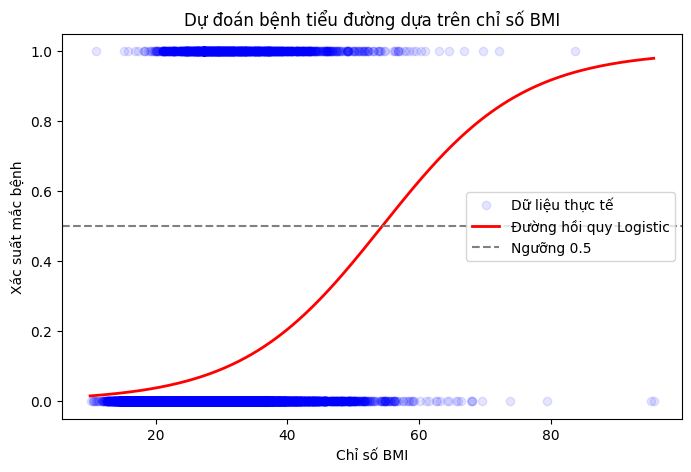

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv('diabetes_prediction_dataset.csv')
df_clean = df[['bmi', 'diabetes']].dropna()


X = df_clean[['bmi']]
y = df_clean['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)
y_du_doan = model.predict(X_test)

print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_du_doan) * 100:.2f}%")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_du_doan))

bmi_ve = np.linspace(X.min().values[0], X.max().values[0], 300).reshape(-1, 1)
duong_sigmoid = model.predict_proba(bmi_ve)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", alpha=0.1, label="Dữ liệu thực tế")
plt.plot(bmi_ve, duong_sigmoid, color="red", linewidth=2, label="Đường hồi quy Logistic")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.title("Dự đoán bệnh tiểu đường dựa trên chỉ số BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.show()